In [123]:
import pandas as pd

In [124]:
import time
from functools import wraps

def timer(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = func(*args, **kwargs)
        end = time.perf_counter()
        print(f"{func.__name__} took {end - start:.3f} seconds")
        return result
    return wrapper

@timer
def load_pbp(path):
    try:
        return pd.read_csv('dataset/play_by_play_2024.csv', low_memory=False)
    except FileNotFoundError:
        print("File not found: {path}")
        return None

pbp = load_pbp("dataset/play_by_play_2024.csv")
#print(pbp.shape)
print(pbp.shape)
print(type(pbp))

load_pbp took 3.158 seconds
(49492, 372)
<class 'pandas.core.frame.DataFrame'>


In [125]:
pbp.head(5)

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1,2024_01_ARI_BUF,2024090801,BUF,ARI,REG,1,NaN,NaN,NaN,...,0,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,40,2024_01_ARI_BUF,2024090801,BUF,ARI,REG,1,ARI,away,BUF,...,0,0,0.257819,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,61,2024_01_ARI_BUF,2024090801,BUF,ARI,REG,1,ARI,away,BUF,...,0,0,-0.200602,NaN,NaN,NaN,NaN,NaN,0.456761,-45.676103
3,83,2024_01_ARI_BUF,2024090801,BUF,ARI,REG,1,ARI,away,BUF,...,0,0,2.028874,1.345418,9.321221,8.0,0.509778,0.363807,0.576656,42.334431
4,108,2024_01_ARI_BUF,2024090801,BUF,ARI,REG,1,ARI,away,BUF,...,0,0,0.754242,0.882798,5.783560,4.0,0.668478,0.255140,0.426443,57.355690


In [126]:
pbp[["game_id","week", "posteam", "defteam","qtr","down","ydstogo","play_type", "yards_gained"]].head(10)

,game_id,week,posteam,defteam,qtr,down,ydstogo,play_type,yards_gained
0,2024_01_ARI_BUF,1,NaN,NaN,1,NaN,0,NaN,NaN
1,2024_01_ARI_BUF,1,ARI,BUF,1,NaN,0,kickoff,0.0
2,2024_01_ARI_BUF,1,ARI,BUF,1,1.0,10,run,3.0
3,2024_01_ARI_BUF,1,ARI,BUF,1,2.0,7,pass,22.0
4,2024_01_ARI_BUF,1,ARI,BUF,1,1.0,10,pass,9.0
5,2024_01_ARI_BUF,1,ARI,BUF,1,2.0,1,run,2.0
6,2024_01_ARI_BUF,1,ARI,BUF,1,1.0,10,run,2.0
7,2024_01_ARI_BUF,1,ARI,BUF,1,2.0,8,run,2.0
8,2024_01_ARI_BUF,1,ARI,BUF,1,3.0,6,pass,8.0
9,2024_01_ARI_BUF,1,ARI,BUF,1,1.0,10,pass,0.0


In [127]:
pbp["play_type"].value_counts(dropna=False)

play_type
pass           20007
run            15043
no_play         4936
kickoff         2955
punt            2119
NaN             1446
extra_point     1308
field_goal      1166
qb_kneel         437
qb_spike          75
Name: count, dtype: int64

In [128]:
pbp[['posteam','down','play_type','yards_gained']].isna().sum()

posteam         2713
down            8009
play_type       1446
yards_gained    1517
dtype: int64

In [129]:
plays = pbp[pbp["play_type"].isin(["pass", "run"])].copy()
print(plays.shape)
plays["play_type"].value_counts()

(35050, 372)


play_type
pass    20007
run     15043
Name: count, dtype: int64

In [130]:
removed = len(pbp) - len(plays)
print("Oroginal rows: ", len(pbp))
print("Kept rows: ", len(plays))
print("Removed rows: ", removed)
print("Percent removed: ", round(removed/ len(pbp) * 100,1))

Oroginal rows:  49492
Kept rows:  35050
Removed rows:  14442
Percent removed:  29.2


In [131]:
plays["yards_gained"].isna().sum()

np.int64(0)

In [132]:
team_stats = (
    plays.groupby("posteam")['yards_gained']
    .agg(plays="count", total_yards='sum',yards_per_play='mean')
    .round(2)
    .sort_values("yards_per_play", ascending=False)
)
team_stats.head(10)

,plays,total_yards,yards_per_play
posteam,,,
BAL,1167,8097.0,6.94
DET,1164,7504.0,6.45
SF,1014,6405.0,6.32
TB,1128,7091.0,6.29
GB,1081,6623.0,6.13
BUF,1202,7251.0,6.03
ARI,1031,6107.0,5.92
ATL,1073,6314.0,5.88
CIN,1069,6229.0,5.83


In [133]:
print(len(team_stats))

32


In [134]:
team_stats.sort_values("total_yards", ascending=False).head(10)

,plays,total_yards,yards_per_play
posteam,,,
BAL,1167,8097.0,6.94
PHI,1341,7725.0,5.76
DET,1164,7504.0,6.45
WAS,1308,7496.0,5.73
BUF,1202,7251.0,6.03
TB,1128,7091.0,6.29
GB,1081,6623.0,6.13
KC,1229,6476.0,5.27
SF,1014,6405.0,6.32


In [135]:
team_stats['rank_ypp'] = team_stats['yards_per_play'].rank(ascending=False)
team_stats['rank_total'] = team_stats['total_yards'].rank(ascending=False)
team_stats['rank_gap'] = (team_stats['rank_ypp'] - team_stats['rank_total']).abs()
team_stats.sort_values('rank_gap',ascending=False).head(5)

,plays,total_yards,yards_per_play,rank_ypp,rank_total,rank_gap
posteam,,,,,,
KC,1229,6476.0,5.27,19.5,8.0,11.5
ARI,1031,6107.0,5.92,7.0,15.0,8.0
PHI,1341,7725.0,5.76,10.0,2.0,8.0
SEA,1018,5661.0,5.56,13.0,20.0,7.0
HOU,1177,6179.0,5.25,21.0,14.0,7.0


In [136]:
print(team_stats['plays'].mean().round(0))

1095.0


In [137]:
team_quality = (
    plays.groupby("posteam")
    .agg(plays=("play_type", "count"),
         success_rate=("success", "mean"),
         epa_per_play=("epa","mean"))
    .round(3)
    .sort_values("epa_per_play", ascending=False)
)
team_quality.head(10)

,plays,success_rate,epa_per_play
posteam,,,
BAL,1167,0.502,0.219
BUF,1202,0.479,0.190
DET,1164,0.505,0.165
WAS,1308,0.478,0.132
TB,1128,0.496,0.129
PHI,1341,0.449,0.119
CIN,1069,0.472,0.090
GB,1081,0.450,0.071
SF,1014,0.461,0.069


In [138]:
top_epa = set(team_quality.head(10).index)
top_ypp = set(team_stats.sort_values("yards_per_play", ascending=False).head(10).index)
top_epa & top_ypp

{'ARI', 'BAL', 'BUF', 'CIN', 'DET', 'GB', 'PHI', 'SF', 'TB'}

In [139]:
print(top_epa - top_ypp) # in EPA top 10, not in yards per play top 10
print(top_ypp - top_epa) # in ypp top 10, not in EPA top 10

{'WAS'}
{'ATL'}


In [140]:
team_stats.loc[["WAS","ATL"]]
team_quality.loc[["WAS", "ATL"]]

,plays,success_rate,epa_per_play
posteam,,,
WAS,1308,0.478,0.132
ATL,1073,0.481,0.034


In [141]:
print(team_stats.loc[["WAS","ATL"]])
print(team_quality.loc[["WAS","ATL"]])
print(team_quality.shape)
print(team_quality.isna().sum())

         plays  total_yards  yards_per_play  rank_ypp  rank_total  rank_gap
posteam                                                                    
WAS       1308       7496.0            5.73      11.0         4.0       7.0
ATL       1073       6314.0            5.88       8.0        11.0       3.0
         plays  success_rate  epa_per_play
posteam                                   
WAS       1308         0.478         0.132
ATL       1073         0.481         0.034
(32, 3)
plays           0
success_rate    0
epa_per_play    0
dtype: int64


In [142]:
bad_plays = plays.groupby("posteam")[["sack", "interception","fumble_lost"]].sum()
print(bad_plays.loc[["WAS", "ATL"]])

         sack  interception  fumble_lost
posteam                                 
WAS      54.0          10.0          7.0
ATL      32.0          19.0          4.0


In [143]:
def team_summary(plays, team):
    team_plays = plays[plays["posteam"] == team]
    return {
        "team": team,
        "plays": len(team_plays),
        "yards_per_play": round(team_plays["yards_gained"].mean(),2),
        "success_rate": round(team_plays["success"].mean(),3),
        "epa_per_play": round(team_plays["epa"].mean(),3)
    }

In [144]:
team_summary(plays, "WAS")

{'team': 'WAS',
 'plays': 1308,
 'yards_per_play': np.float64(5.73),
 'success_rate': np.float64(0.478),
 'epa_per_play': np.float64(0.132)}

In [145]:
print(round(plays["yards_gained"].mean(),2))
print(round(plays["epa"].mean(),3))
print(len(plays))

5.51
0.01
35050


In [146]:
class TeamAnalyzer:
    def __init__(self,plays,team):
        self.team = team
        self.data = plays[plays["posteam"] == team]

    def summary(self):
        return {
            "team": self.team,
            "plays": len(self.data),
            "yards_per_play": round(self.data["yards_gained"].mean(),2),
            "success_rate": round(self.data['success'].mean(), 3),
            "epa_per_play": round(self.data["epa"].mean(),3)
        }

    def bad_play_per_100(self):
        n = len(self.data)
        counts = self.data[["sack","interception", "fumble_lost"]].sum()
        total = int(counts.sum())
        return {
            "plays": n,
            "bad_plays": total,
            "bad_per_100": round(total / n * 100, 2)
        }
    

was = TeamAnalyzer(plays, "WAS")
was.summary()
    

{'team': 'WAS',
 'plays': 1308,
 'yards_per_play': np.float64(5.73),
 'success_rate': np.float64(0.478),
 'epa_per_play': np.float64(0.132)}

In [147]:
atl = TeamAnalyzer(plays, "ATL")
atl.summary()

{'team': 'ATL',
 'plays': 1073,
 'yards_per_play': np.float64(5.88),
 'success_rate': np.float64(0.481),
 'epa_per_play': np.float64(0.034)}

In [148]:
was = TeamAnalyzer(plays, "WAS")
was.bad_play_per_100()

{'plays': 1308, 'bad_plays': 71, 'bad_per_100': 5.43}

In [149]:
atl1 = TeamAnalyzer(plays, "ATL")
atl1.bad_play_per_100()

{'plays': 1073, 'bad_plays': 55, 'bad_per_100': 5.13}

In [150]:
def read_chunks(path, chunksize =10000):
    for chunk in pd.read_csv(path, chunksize=chunksize, low_memory=False):
        yield chunk

n_chunks = 0
total_rows = 0
for chunk in read_chunks("dataset/play_by_play_2024.csv"):
    n_chunks += 1
    total_rows += len(chunk)

for i,chunk in enumerate(read_chunks("dataset/play_by_play_2024.csv"), start=1):
    print(i, len(chunk))

print(n_chunks,total_rows)

1 10000
2 10000
3 10000
4 10000
5 9492
5 49492


In [151]:
play_counts = {}

for chunk in read_chunks("dataset/play_by_play_2024.csv"):
    offense = chunk[chunk["play_type"].isin(["run","pass"])]
    counts = offense["posteam"].value_counts()
    for team, n in counts.items():
        play_counts[team] = play_counts.get(team,0) + n

print(len(play_counts), sum(play_counts.values()))
print(play_counts["WAS"],play_counts["ATL"])

32 35050
1308 1073


In [152]:
for chunk in read_chunks("dataset/play_by_play_2024.csv"):
    offense = chunk[chunk["play_type"].isin(["run","pass"])]
    print(i,(offense['posteam'] == "WAS").sum())

5 178
5 322
5 247
5 150
5 411


In [153]:
import numpy as np
epa = plays["epa"].to_numpy()

print(epa.shape, epa.dtype)
print(np.isnan(epa).sum())
print(np.nanmean(epa).round(3), np.nanstd(epa).round(3))
print(np.nanpercentile(epa, [25,50,75]).round(3))

(35050,) float64
0
0.01 1.387
[-0.627 -0.164  0.717]


In [154]:
print((epa < 0).mean().round(3))
print(np.sort(epa)[:5].round(2))
print(np.sort(epa)[-5:].round(2))

0.56
[-12.69 -12.57 -11.45 -10.95 -10.5 ]
[7.26 7.67 8.2  8.49 8.54]


In [155]:
posteam = plays["posteam"].to_numpy()
was_mask = posteam == "WAS"
atl_mask = posteam == "ATL"

print(was_mask.sum(), atl_mask.sum())
print(epa[was_mask].mean().round(3), epa[atl_mask].mean().round(3))

big = epa > 1
bad = epa < -1

for name, mask in [("WAS", was_mask), ("ATL", atl_mask)]:
    print(name,big[mask].mean().round(3), bad[mask].mean().round(3))

label = np.where(epa < 0, "negative", "zero or positive")
print(np.unique(label, return_counts=True))

1308 1073
0.132 0.034
WAS 0.196 0.127
ATL 0.181 0.133
(array(['negative', 'zero or positive'], dtype='<U16'), array([19643, 15407]))


In [156]:
team_all = team_stats.merge(
    team_quality,
    left_index=True,
    right_index=True,
    suffixes=("_stats","_quality")
)

print(team_all.shape)
print(team_all.columns.tolist())
print((team_all["plays_stats"] == team_all["plays_quality"]).all())

team_all["rank_epa"] = team_all["epa_per_play"].rank(ascending=False)
team_all["rank_diff"] = team_all["rank_ypp"] - team_all["rank_epa"]
print(team_all.sort_values("rank_diff")[["yards_per_play", "epa_per_play", "rank_ypp", "rank_epa", "rank_diff"]].head(5))
print(team_all.sort_values("rank_diff")[["yards_per_play", "epa_per_play", "rank_ypp", "rank_epa", "rank_diff"]].tail(5))

(32, 9)
['plays_stats', 'total_yards', 'yards_per_play', 'rank_ypp', 'rank_total', 'rank_gap', 'plays_quality', 'success_rate', 'epa_per_play']
True
         yards_per_play  epa_per_play  rank_ypp  rank_epa  rank_diff
posteam                                                             
IND                5.52        -0.057      16.0      24.5       -8.5
SEA                5.56        -0.030      13.0      20.0       -7.0
NO                 5.31        -0.057      18.0      24.5       -6.5
SF                 6.32         0.069       3.0       9.0       -6.0
ATL                5.88         0.034       8.0      12.0       -4.0
         yards_per_play  epa_per_play  rank_ypp  rank_epa  rank_diff
posteam                                                             
DEN                5.34         0.015      17.0      13.0        4.0
NYJ                5.22        -0.013      22.0      17.0        5.0
CHI                4.57        -0.082      32.0      26.0        6.0
WAS                5.73

In [157]:
print(team_all.loc[["WAS", "ATL"], ["rank_ypp", "rank_epa", "rank_diff"]])

         rank_ypp  rank_epa  rank_diff
posteam                               
WAS          11.0       4.0        7.0
ATL           8.0      12.0       -4.0


In [158]:
team_week = (
    plays.groupby(["posteam", "week"])
                   .agg(plays=("play_type", "count"),
                        epa_per_play=("epa", "mean"))
                        .round(3))


print(team_week.shape)
print(team_week.index.names)
print(team_week.loc["WAS"].head(5))
print(team_week.loc["WAS", 1])

wide = team_week["epa_per_play"].unstack("week")
print(wide.shape)
print(wide.loc["WAS"].isna().sum())
print(wide.loc["WAS"])

(570, 2)
['posteam', 'week']
      plays  epa_per_play
week                     
1        56         0.121
2        67         0.156
3        55         0.515
4        68         0.416
5        65         0.084
plays           56.000
epa_per_play     0.121
Name: (WAS, 1), dtype: float64
(32, 22)
2
week
1     0.121
2     0.156
3     0.515
4     0.416
5     0.084
6     0.102
7     0.269
8     0.075
9     0.312
10   -0.136
11   -0.117
12   -0.029
13    0.292
14      NaN
15    0.072
16   -0.066
17    0.222
18    0.087
19    0.113
20    0.288
21   -0.089
22      NaN
Name: WAS, dtype: float64


In [159]:
print(wide.loc["WAS"], [19,20,21,22])

week
1     0.121
2     0.156
3     0.515
4     0.416
5     0.084
6     0.102
7     0.269
8     0.075
9     0.312
10   -0.136
11   -0.117
12   -0.029
13    0.292
14      NaN
15    0.072
16   -0.066
17    0.222
18    0.087
19    0.113
20    0.288
21   -0.089
22      NaN
Name: WAS, dtype: float64 [19, 20, 21, 22]


In [160]:
plays["game_date"] = pd.to_datetime(plays["game_date"])
print(plays["game_date"].dtype)

games = plays.drop_duplicates("game_id")[["game_id", "game_date"]]
print(len(games))
print(games["game_date"].dt.day_name().value_counts())
print(games["game_date"].min(), games["game_date"].mean())
print(games["game_date"].max())
print(games.sort_values("game_date").tail(1))

datetime64[ns]
285
game_date
Sunday       229
Monday        22
Thursday      19
Saturday      11
Friday         2
Wednesday      2
Name: count, dtype: int64
2024-09-05 00:00:00 2024-11-09 11:27:09.473684224
2025-02-09 00:00:00
              game_id  game_date
49318  2024_22_KC_PHI 2025-02-09


In [161]:
print(games[games["game_date"] == "2024-11-28"])

               game_id  game_date
31245  2024_13_CHI_DET 2024-11-28
32483   2024_13_MIA_GB 2024-11-28
32657  2024_13_NYG_DAL 2024-11-28


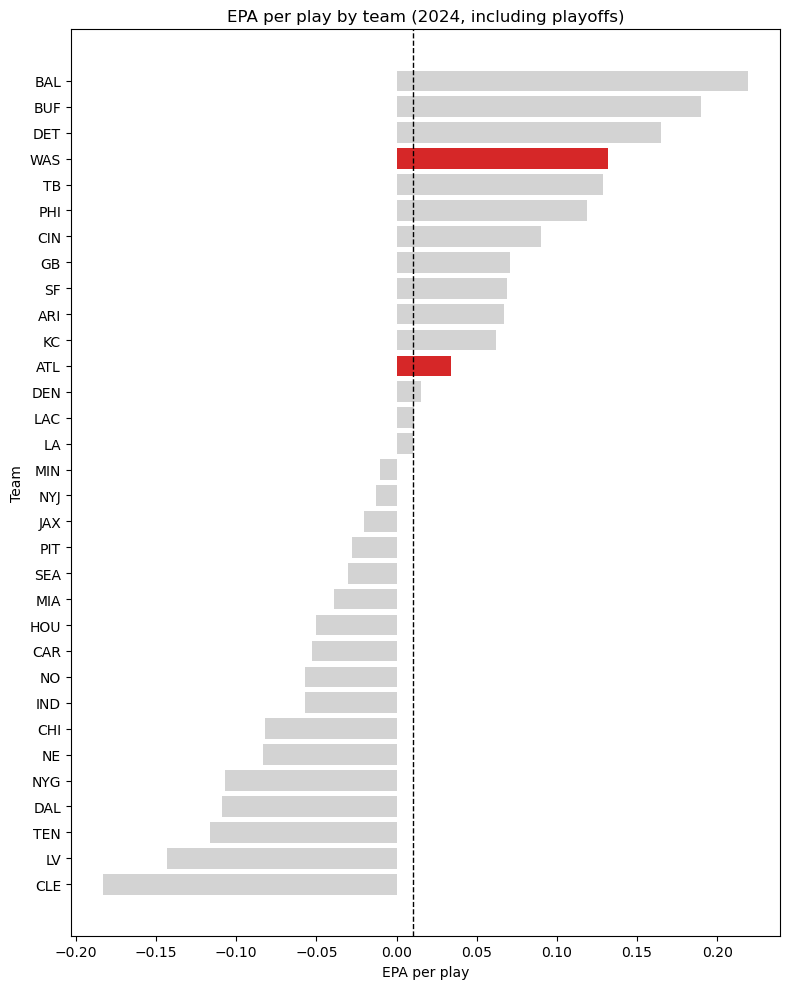

In [162]:
import os
import matplotlib.pyplot as plt

os.makedirs("charts", exist_ok=True)

data = team_quality.sort_values("epa_per_play")
colors = ["tab:red" if t in ("WAS", "ATL") else "lightgray" for t in data.index]

fig, ax = plt.subplots(figsize=(8,10))
ax.barh(data.index, data["epa_per_play"], color= colors)
ax.axvline(0.01, color="black", linestyle="--", linewidth = 1)
ax.set_title("EPA per play by team (2024, including playoffs)")
ax.set_xlabel("EPA per play")
ax.set_ylabel("Team")
plt.tight_layout()
plt.savefig("Charts/epa_per_team.png", dpi=150)
plt.show()

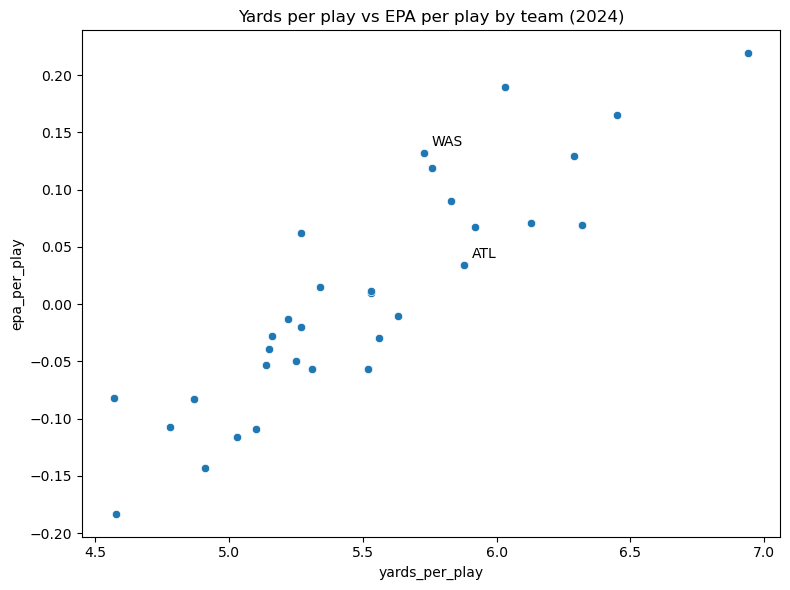

                yards_per_play  epa_per_play
yards_per_play           1.000         0.888
epa_per_play             0.888         1.000


In [163]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8,6))
sns.scatterplot(data=team_all, x="yards_per_play", y="epa_per_play", ax=ax)

for team in ["WAS", "ATL"]:
    row = team_all.loc[team]
    ax.annotate(team, (row["yards_per_play"], row["epa_per_play"]),
                xytext=(5,5), textcoords="offset points")

ax.set_title("Yards per play vs EPA per play by team (2024)")
plt.tight_layout()
plt.savefig("charts/ypp_vs_epa.png", dpi=150)
plt.show()
print(team_all[["yards_per_play", "epa_per_play"]].corr().round(3))

In [164]:
import plotly.express as px

fig = px.scatter(
    team_all.reset_index(),
    x="yards_per_play",
    y="epa_per_play",
    hover_name="posteam",
    hover_data={"rank_ypp": True, "rank_epa":True},
    title="Yards per play vs EPA per play by team (2024)"
)
fig.write_html("charts/ypp_vs_epa.html")
fig.show()

In [165]:
key_cols = ["posteam", "defteam", "down", "ydstogo", "yards_gained",
            "epa", "success", "week", "game_date"]

print(plays[key_cols].isna().sum())
print(plays.duplicated(["game_id", "play_id"]).sum())
print(plays["yards_gained"].describe().round(2))
print(plays["epa"].describe().round(3))

posteam           0
defteam           0
down            148
ydstogo           0
yards_gained      0
epa               0
success           0
week              0
game_date         0
dtype: int64
0
count    35050.00
mean         5.51
std          8.59
min        -24.00
25%          0.00
50%          3.00
75%          8.00
max         98.00
Name: yards_gained, dtype: float64
count    35050.000
mean         0.010
std          1.387
min        -12.689
25%         -0.627
50%         -0.164
75%          0.717
max          8.541
Name: epa, dtype: float64


In [166]:
missing_down = plays[plays["down"].isna()]
print(len(missing_down))
print(missing_down["two_point_attempt"].value_counts())
print(missing_down["play_type"].value_counts())

148
two_point_attempt
1.0    148
Name: count, dtype: int64
play_type
pass    110
run      38
Name: count, dtype: int64


In [167]:
findings = {
    "rows loaded": len(pbp),
    "run and pass plays kept": len(plays),
    "teams": plays["posteam"].nunique(),
    "league yards per play": round(plays["yards_gained"].mean(),2),
    "league EPA per play": round(plays["epa"].mean(),3),
    "share of plays with negative EPA": round((plays["epa"] < 0).mean(),3), 
    "best team by EPA": team_quality["epa_per_play"].idxmax(),
    "best EPA per play": team_quality["epa_per_play"].max(),
    "worst team by EPA": team_quality["epa_per_play"].idxmin(),
    "correlation, yards per play and EPA per play": round(team_all["yards_per_play"].corr(team_all["epa_per_play"]),3)
}
for key, value in findings.items():
    print(f"{key}: {value}")

rows loaded: 49492
run and pass plays kept: 35050
teams: 32
league yards per play: 5.51
league EPA per play: 0.01
share of plays with negative EPA: 0.56
best team by EPA: BAL
best EPA per play: 0.219
worst team by EPA: CLE
correlation, yards per play and EPA per play: 0.888


I loaded 49,492 plays from the 2024 NFL season, including the playoffs, and kept the 35,050 run and pass plays across 32 teams. The other 14,442 plays (29.2%) were kickoffs, punts, field goals and other non offense plays, which I removed because this analysis measures offense. I measured each team with three numbers: yards per play, success rate and EPA per play. Across the league, the average play gained 5.51 yards and added 0.01 expected points, and 56% of plays had negative EPA. Teams that gain more yards per play usually have higher EPA per play: the correlation across the 32 teams is 0.888, so about 79% of the team to team variation in EPA per play moves with yards per play. Yards do not tell the whole story, though. WAS gained 5.73 yards per play and ATL gained 5.88, yet WAS added 0.132 expected points per play against 0.034 for ATL. EPA can differ from yards because it accounts for the down, distance and field position of each play, so the same gain can help a drive or do nothing for it, and costly plays like interceptions count against a team. One limit is that this covers a single season, and part of the gap between WAS and ATL is still unexplained, because the big play and bad play cutoffs I used were my own choice and ignore how large each play was.

In [170]:
import sqlite3
cols = ["game_id", "play_id", "week", "game_date", "posteam", "defteam", "down",
        "ydstogo", "play_type", "yards_gained", "epa", "success", "sack", "interception", "fumble_lost"]

db_plays = plays[cols].copy()
db_plays["game_date"] = db_plays["game_date"].dt.strftime("%Y-%m-%d")

conn = sqlite3.connect("nfl.db")
db_plays.to_sql("plays", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT COUNT(*) AS n FROM plays", conn))

query = """
SELECT posteam,
COUNT(*) AS plays,
ROUND(AVG(yards_gained),2) AS yards_per_play,
ROUND(AVG(success), 3) AS success_rate,
ROUND(AVG(epa), 3) AS epa_per_play

FROM plays
GROUP BY posteam
ORDER BY epa_per_play DESC
LIMIT 5
"""

print(pd.read_sql(query,conn))

       n
0  35050
  posteam  plays  yards_per_play  success_rate  epa_per_play
0     BAL   1167            6.94         0.502         0.219
1     BUF   1202            6.03         0.479         0.190
2     DET   1164            6.45         0.505         0.165
3     WAS   1308            5.73         0.478         0.132
4      TB   1128            6.29         0.496         0.129


In [173]:
games_tbl = pbp.drop_duplicates("game_id")[["game_id", "home_team", "away_team", "home_score", "away_score"]]
games_tbl.to_sql("games", conn, if_exists="replace", index=False)
print(pd.read_sql("SELECT COUNT(*) AS n FROM games", conn))

query = """
SELECT case
when (p.posteam = g.home_team AND g.home_score > g.away_score)
OR (p.posteam = g.away_team AND g.away_score > g.home_score) THEN 'win'
ELSE 'loss or tie'
END AS outcome,
COUNT(DISTINCT p.game_id) AS games,
COUNT(*) AS plays,
ROUND(avg(p.epa), 3) AS epa_per_play

FROM plays p
JOIN games g ON p.game_id = g.game_id
WHERE p.posteam = 'WAS'
GROUP BY outcome
"""

print(pd.read_sql(query,conn))

     n
0  285
       outcome  games  plays  epa_per_play
0  loss or tie      6    381        -0.032
1          win     14    927         0.200


In [174]:
query = """
SELECT week,
epa_per_play,
ROUND(AVG(epa_per_play) OVER (
ORDER BY week
ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 3) AS rolling_3
from (
SELECT week, ROUND(AVG(epa), 3) AS epa_per_play
FROM plays
WHERE posteam = 'WAS'
GROUP BY week) as wk
ORDER BY week
"""
print(pd.read_sql(query, conn))

    week  epa_per_play  rolling_3
0      1         0.121      0.121
1      2         0.156      0.139
2      3         0.515      0.264
3      4         0.416      0.362
4      5         0.084      0.338
5      6         0.102      0.201
6      7         0.269      0.152
7      8         0.075      0.149
8      9         0.312      0.219
9     10        -0.136      0.084
10    11        -0.117      0.020
11    12        -0.029     -0.094
12    13         0.292      0.049
13    15         0.072      0.112
14    16        -0.066      0.099
15    17         0.222      0.076
16    18         0.087      0.081
17    19         0.113      0.141
18    20         0.288      0.163
19    21        -0.089      0.104


## Summary of findings

I loaded 49,492 plays from the 2024 NFL season, including the playoffs, and kept the 35,050 run and pass plays across 32 teams. The other 14,442 plays (29.2%) were kickoffs, punts, field goals and other non offense plays, which I removed because this analysis measures offense. I measured each team with three numbers: yards per play, success rate and EPA per play. Across the league, the average play gained 5.51 yards and added 0.01 expected points, and 56% of plays had negative EPA. Teams that gain more yards per play usually have higher EPA per play: the correlation across the 32 teams is 0.888, so about 79% of the team to team variation in EPA per play moves with yards per play. Yards do not tell the whole story, though. WAS gained 5.73 yards per play and ATL gained 5.88, yet WAS added 0.132 expected points per play against 0.034 for ATL. EPA can differ from yards because it accounts for the down, distance and field position of each play, so the same gain can help a drive or do nothing for it, and costly plays like interceptions count against a team. One limit is that this covers a single season, and part of the gap between WAS and ATL is still unexplained, because the big play and bad play cutoffs I used were my own choice and ignore how large each play was.